# Tutorial 1b: Lens Properties and Prescription Reports

**In this tutorial:** paraxial (first-order) properties such as focal length, f-number and pupil positions, and how to turn a lens into a prescription report in the console or as a PDF.


*Last verified against Optiland v0.6.1.*

The first half of this tutorial shows how to read common optical properties back out of a lens, including:

- Front and back focal length
- Front and back principal, focal and nodal plane locations
- Aperture information, such as F-Number, entrance or exit pupil diameter, etc.
- Locations of entrance/exit pupils
- Optical invariant
- Marginal/chief rays

## Start from a system that already works

Rather than building a lens from scratch — that is [Tutorial 1a](Tutorial_1a_Optiland_for_Beginners.ipynb) — this tutorial loads one of Optiland's sample designs, a Cooke triplet, and reads its properties back out. Run the cell below and you have a real, traceable system in one line.

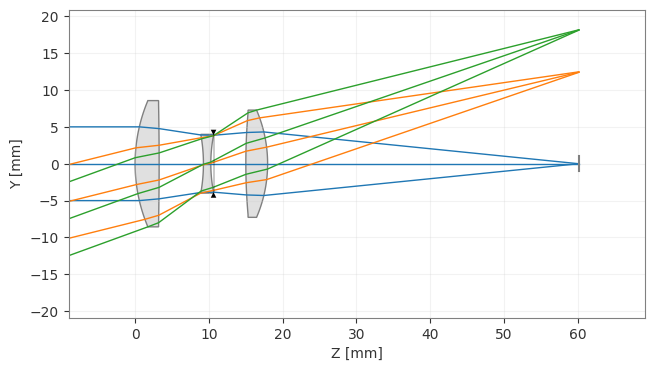

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [1]:
from optiland.samples.objectives import CookeTriplet

lens = CookeTriplet()
lens.draw()

Every quantity in this tutorial follows the conventions described on the [Conventions](../conventions.rst) page: lens units are millimeters, wavelengths are micrometers, angles are degrees, and the sign of a radius or thickness follows the direction of propagation.

In [2]:
print(f"Front focal length: {lens.paraxial.f1():.1f} mm")
print(f"Focal length: {lens.paraxial.f2():.1f} mm")
print(f"Front focal point: {lens.paraxial.F1():.1f} mm")
print(f"Back focal point: {lens.paraxial.F2():.1f} mm")
print(f"Front principal plane: {lens.paraxial.P1():.1f} mm")
print(f"Back principal plane: {lens.paraxial.P2():.1f} mm")
print(f"Front nodal plane: {lens.paraxial.N1():.1f} mm")
print(f"Back nodal plane: {lens.paraxial.N2():.1f} mm")

Front focal length: -50.0 mm
Focal length: 50.0 mm
Front focal point: -37.3 mm
Back focal point: 0.2 mm
Front principal plane: 12.7 mm
Back principal plane: -49.8 mm
Front nodal plane: 12.7 mm
Back nodal plane: -49.8 mm


Regarding cardinal points, Optiland defines object space quantities relative to the first lens surface (index 1) and image space quantities relative to the image surface. This applies to the pupil locations too: `EPL()` is relative to surface 1 and `XPL()` is relative to the image surface. If you need the entrance pupil on the same axial coordinate as surface positions, use `lens.paraxial.entrance_pupil_axial_position()` (`entrance_pupil_z()` is a deprecated alias).

In [3]:
print(f"Entrance pupil diameter: {lens.paraxial.EPD():.1f} mm")
print(f"Exit pupil diameter: {lens.paraxial.XPD():.1f} mm")

Entrance pupil diameter: 10.0 mm
Exit pupil diameter: 10.2 mm


In [4]:
print(f"Entrance pupil position: {lens.paraxial.EPL():.1f} mm")
print(f"Exit pupil position: {lens.paraxial.XPL():.1f} mm")

Entrance pupil position: 11.5 mm
Exit pupil position: -51.0 mm


Magnification is generally computed for finite objects and not for systems like the one we're analyzing here. We compute it only as an illustration.

In [5]:
print(f"Image-space F-Number: {lens.paraxial.FNO():.1f}")
print(f"Magnification: {lens.paraxial.magnification():.1f}")
print(f"Invariant: {lens.paraxial.invariant():.3f}")

Image-space F-Number: 5.0
Magnification: -0.0
Invariant: -1.820


In [6]:
print("Marginal Ray: ")

ya, ua = lens.paraxial.marginal_ray()
for k in range(len(ya)):
    print(f"\tSurface {k}: y = {ya[k, 0]:.3f}, u = {ua[k, 0]:.3f}")

Marginal Ray: 
	Surface 0: y = 5.000, u = 0.000
	Surface 1: y = 5.000, u = -0.087
	Surface 2: y = 4.716, u = -0.148
	Surface 3: y = 3.826, u = -0.025
	Surface 4: y = 3.801, u = 0.076
	Surface 5: y = 4.162, u = 0.027
	Surface 6: y = 4.242, u = -0.100
	Surface 7: y = 0.021, u = -0.100


In [7]:
print("Chief Ray: ")

yb, ub = lens.paraxial.chief_ray()
for k in range(len(yb)):
    print(f"\tSurface {k}: y = {yb[k, 0]:.3f}, u = {ub[k, 0]:.3f}")

Chief Ray: 
	Surface 0: y = -4.190, u = 0.364
	Surface 1: y = -4.190, u = 0.297
	Surface 2: y = -3.221, u = 0.487
	Surface 3: y = -0.295, u = 0.295
	Surface 4: y = -0.000, u = 0.479
	Surface 5: y = 2.275, u = 0.284
	Surface 6: y = 3.113, u = 0.356
	Surface 7: y = 18.125, u = 0.356



---
## Part 2: Prescription Generator



In [8]:
from optiland.prescription import Prescription
from optiland.samples.objectives import CookeTriplet

## 1. What is a prescription?

A prescription summarizes an optical system across five sections:

| Section | Contents |
|---|---|
| **System Overview** | Name, aperture type, fields, wavelengths |
| **First-Order Properties** | EFL, BFL, FFL, magnification, NAs, pupil positions |
| **Surface Geometry Table** | Radius, conic, thickness, aperture stop flag for every surface |
| **Surface Material Table** | Material name, nd, Abbe number, type for every surface |
| **Seidel Aberrations** | W040, W131, W222, W220, W311 and their totals |

## 2. Generating a prescription for a sample lens

`Prescription(lens).view()` prints a Rich-formatted table to the console.
This requires the optional `rich` package (`pip install "optiland[prescription]"`).

In [9]:
lens = CookeTriplet()

p = Prescription(lens)
p.view()

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Optical Prescription — Unnamed System                                                                           │
╰──────────────────────────────────────── Generated: 2026-11-22 09:52 UTC ────────────────────────────────────────╯

───────────────────────────────────────────────── System Overview ─────────────────────────────────────────────────

 Name              (unnamed)    
  Surfaces          6            
  Stop Surface      4.0000       
  Aperture Type     EPDAperture  
  Aperture Value    10.0000      
  Object Distance   ∞            
  Image Distance    42.2078     

 Wavelengths

 #   Wavelength (µm)   Primary  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1   0.4800                     
  2   0.5500            ✓        
  3   0.6500

 Fields

... (5 outputs left out)

──────────────────────────────────────────── Surface Data — Materials ─────────────────────────────────────────────

 S#   Material   nd       Vd        Semi-Diameter (mm)   Coating  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0    Air        1.0000   —         —                    —        
  1    SK16       1.6204   60.2809   —                    —        
  2    Air        1.0000   —         —                    —        
  3    F2         1.6200   36.3665   —                    —        
  4    Air        1.0000   —         —                    —        
  5    SK16       1.6204   60.2809   —                    —        
  6    Air        1.0000   —         —                    —        
  7    Air        1.0000   —         —                    —       

───────────────────────────────────────── Seidel Aberration Coefficients ──────────────────────────────────────────

 S#      SI (Sph)    SII (Coma)   SIII (Astig)   SIV (Petz)   SV (Dist)   CL (LCA)    CT (TCA)   
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1       -0.013855   -0.010591    -0.008096      -0.057727    -0.050318   -0.014876   -0.011372  
  2       -0.011256   0.035011     -0.108897      -0.002916    0.347781    -0.009820   0.030545   
  3       0.052115    -0.081389    0.127106       0.057268     -0.287939   0.026690    -0.041683  
  4       0.024135    0.043874     0.079756       0.062690     0.258946    0.021798    0.039625   
  5       -0.004080   -0.016132    -0.063784      -0.015948    -0.315255   -0.006996   -0.027660  
  6       -0.054020   0.030462     -0.017178      -0.069082    0.048643    -0.018366   0.010357   
  Total   -0.006960   0.001235     0.008907       -0.025716    0.001859    -0.001569   -0.000187

## 3. Prescription output fields — the Document model

`Prescription.build()` returns a `Document` object without printing anything.
You can inspect each section programmatically.

In [10]:
doc = p.build()

print("Document title  :", doc.title)
print("Generated at    :", doc.generated_at)
print("Number of sections:", len(doc.sections))

for section in doc.sections:
    print(f"  Section: {section.title!r}")

Document title  : Optical Prescription — Unnamed System
Generated at    : 2026-11-22 09:52 UTC
Number of sections: 5
  Section: 'System Overview'
  Section: 'First-Order Properties'
  Section: 'Surface Data — Geometry'
  Section: 'Surface Data — Materials'
  Section: 'Seidel Aberration Coefficients'


In [11]:
# Inspect the first-order properties section (KeyValueBlock rows)
first_order_section = doc.sections[1]
print(f"Section: {first_order_section.title}")
for block in first_order_section.blocks:
    if hasattr(block, "rows"):  # KeyValueBlock
        for label, value in block.rows:
            print(f"  {label}: {value}")

Section: First-Order Properties
  Effective Focal Length (EFL): 49.9998
  Front Focal Length (FFL): -49.9998
  Back Focal Length (BFL): 0.2071
  Front Principal Plane (P1): 12.6541
  Back Principal Plane (P2): -49.7927
  Front Nodal Plane (N1): 12.6541
  Back Nodal Plane (N2): -49.7927
  Image-Space F/#: 5.0000
  Entrance Pupil Diameter: 10.0000
  Entrance Pupil Location: 11.5122
  Exit Pupil Diameter: 10.2337
  Exit Pupil Location: -50.9613
  Transverse Magnification: -0.0000
  Lagrange Invariant: -1.8199


## 4. Saving to plain text

`Prescription.save(path)` infers the renderer from the file extension.
Any extension other than `.pdf` produces a plain-text report.

In [12]:
p.save("cooke_triplet.txt")

# Verify the file was written 
with open("cooke_triplet.txt", "r", encoding="utf-8") as f:
    content = f.read()

print(content[:800])  # print first 800 characters

══════════════════════════════════════════════════════════════════════
  OPTICAL PRESCRIPTION — UNNAMED SYSTEM
  Generated: 2026-11-22 09:52 UTC
══════════════════════════════════════════════════════════════════════

┌─ System Overview ──────────────────────────────────────────────────┐
  Name              (unnamed)
  Surfaces          6
  Stop Surface      4.0000
  Aperture Type     EPDAperture
  Aperture Value    10.0000
  Object Distance   ∞
  Image Distance    42.2078

  Wavelengths
  #   Wavelength (µm)   Primary
  ─   ───────────────   ───────
  1   0.4800                   
  2   0.5500            ✓      
  3   0.6500                   

  Fields
  #   Type         X        Y         Weight
  ─   ──────────   ──────   ───────   ──────
  1   AngleField   0.0000   0.0000    1.0000
  2


## 5. Exporting to PDF

Pass a `.pdf` path to `save()`. This requires the `reportlab` package
(`pip install "optiland[prescription]"`).

In [13]:
try:
    p.save("cooke_triplet.pdf")
    print("PDF saved to cooke_triplet.pdf")
except ImportError:
    print("reportlab not installed — skipping PDF export.")
    print("Install with: pip install reportlab")

PDF saved to cooke_triplet.pdf


## 6. Custom sections

The `Prescription` constructor accepts an optional `sections` list. You can pass a subset of
the default sections or combine built-in sections in any order.

In [14]:
from optiland.prescription import (
    FirstOrderSection,
    SurfaceGeometryTableSection,
    SystemOverviewSection,
)

# Minimal prescription: overview + first-order only
p_minimal = Prescription(
    lens,
    sections=[SystemOverviewSection(), FirstOrderSection(), SurfaceGeometryTableSection()],
)
p_minimal.view()

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Optical Prescription — Unnamed System                                                                           │
╰──────────────────────────────────────── Generated: 2026-11-22 09:52 UTC ────────────────────────────────────────╯

───────────────────────────────────────────────── System Overview ─────────────────────────────────────────────────

 Name              (unnamed)    
  Surfaces          6            
  Stop Surface      4.0000       
  Aperture Type     EPDAperture  
  Aperture Value    10.0000      
  Object Distance   ∞            
  Image Distance    42.2078     

 Wavelengths

 #   Wavelength (µm)   Primary  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1   0.4800                     
  2   0.5500            ✓        
  3   0.6500

 Fields

 #   Type         X        Y         Weight  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1   AngleField   0.0000   0.0000    1.0000  
  2   AngleField   0.0000   14.0000   1.0000  
  3   AngleField   0.0000   20.0000   1.0000

───────────────────────────────────────────── First-Order Properties ──────────────────────────────────────────────

 Effective Focal Length (EFL)   49.9998   
  Front Focal Length (FFL)       -49.9998  
  Back Focal Length (BFL)        0.2071    
  Front Principal Plane (P1)     12.6541   
  Back Principal Plane (P2)      -49.7927  
  Front Nodal Plane (N1)         12.6541   
  Back Nodal Plane (N2)          -49.7927  
  Image-Space F/#                5.0000    
  Entrance Pupil Diameter        10.0000   
  Entrance Pupil Location        11.5122   
  Exit Pupil Diameter            10.2337   
  Exit Pupil Location            -50.9613  
  Transverse Magnification       -0.0000   
  Lagrange Invariant             -1.8199  

───────────────────────────────────────────── Surface Data — Geometry ─────────────────────────────────────────────

 S#   Type       Radius (mm)   Thickness (mm)   Conic    Stop   Comment  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0    Plane      ∞             ∞                —                        
  1    standard   22.0136       3.2590           0.0000                   
  2    standard   -435.7604     6.0076           0.0000                   
  3    standard   -22.2133      1.0000           0.0000                   
  4    standard   20.2919       4.7504           0.0000   ✓               
  5    standard   79.6836       2.9521           0.0000                   
  6    standard   -18.3953      42.2078          0.0000                   
  7    standard   ∞             0.0000           —                       

## 7. Custom prescription: user-defined lens

Build a cemented doublet from scratch and read off key properties from the prescription.

In [15]:
from optiland.optic import Optic

doublet = Optic(name="Achromatic Doublet f/4")
doublet.surfaces.add(index=0, radius=float("inf"), thickness=float("inf"))
doublet.surfaces.add(index=1, radius=61.5, thickness=6.0, material="N-BK7", is_stop=True)
doublet.surfaces.add(index=2, radius=-44.6, thickness=2.5, material="N-F2")
doublet.surfaces.add(index=3, radius=-129.0, thickness=0.0)
doublet.surfaces.add(index=4)  # image plane
doublet.set_aperture(aperture_type="EPD", value=25.0)
doublet.fields.set_type("angle")
doublet.fields.add(y=0.0)
doublet.wavelengths.add(value=0.4861)                  # F-line
doublet.wavelengths.add(value=0.5876, is_primary=True)  # d-line
doublet.wavelengths.add(value=0.6563)                  # C-line
doublet.updater.image_solve()

Prescription(doublet).view()

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Optical Prescription — Achromatic Doublet f/4                                                                   │
╰──────────────────────────────────────── Generated: 2026-11-22 09:52 UTC ────────────────────────────────────────╯

───────────────────────────────────────────────── System Overview ─────────────────────────────────────────────────

 Name              Achromatic Doublet f/4  
  Surfaces          3                       
  Stop Surface      1.0000                  
  Aperture Type     EPDAperture             
  Aperture Value    25.0000                 
  Object Distance   ∞                       
  Image Distance    88.9120                

 Wavelengths

 #   Wavelength (µm)   Primary  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1   0.4861                     
  2   0.5876            ✓        
  3   0.6563

 Fields

... (5 outputs left out)

──────────────────────────────────────────── Surface Data — Materials ─────────────────────────────────────────────

 S#   Material   nd       Vd        Semi-Diameter (mm)   Coating  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0    Air        1.0000   —         —                    —        
  1    N-BK7      1.5168   64.1673   —                    —        
  2    N-F2       1.6200   36.4309   —                    —        
  3    Air        1.0000   —         —                    —        
  4    Air        1.0000   —         —                    —

───────────────────────────────────────── Seidel Aberration Coefficients ──────────────────────────────────────────

 S#      SI (Sph)    SII (Coma)   SIII (Astig)   SIV (Petz)   SV (Dist)   CL (LCA)    CT (TCA)   
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1       -0.023577   0.000000     0.000000       -0.000000    0.000000    -0.026992   -0.000000  
  2       0.052430    0.000000     0.000000       0.000000     0.000000    0.064830    -0.000000  
  3       -0.065064   -0.000000    0.000000       -0.000000    0.000000    -0.057179   0.000000   
  Total   -0.036210   0.000000     0.000000       0.000000     0.000000    -0.019340   0.000000  

In [16]:
# Read off first-order properties programmatically
doc = Prescription(doublet).build()
fo_section = doc.sections[1]  # FirstOrderSection

print(f"Section: {fo_section.title}")
for block in fo_section.blocks:
    if hasattr(block, "rows"):
        for label, value in block.rows:
            print(f"  {label:30s}: {value}")

Section: First-Order Properties


  Effective Focal Length (EFL)  : 92.8832
  Front Focal Length (FFL)      : -92.8832
  Back Focal Length (BFL)       : 0.0000
  Front Principal Plane (P1)    : 1.6107
  Back Principal Plane (P2)     : -92.8832
  Front Nodal Plane (N1)        : 1.6107
  Back Nodal Plane (N2)         : -92.8832
  Image-Space F/#               : 3.7153
  Entrance Pupil Diameter       : 25.0000
  Entrance Pupil Location       : 0.0000
  Exit Pupil Diameter           : 25.4412
  Exit Pupil Location           : -94.5223
  Transverse Magnification      : -0.0000
  Lagrange Invariant            : -0.0000


## Conclusion

In this tutorial you learned how to:

- Generate a prescription with `Prescription(lens).view()` for Rich console output
- Inspect the `Document` model programmatically via `Prescription.build()`
- Save reports to plain text (`.txt`) and PDF (`.pdf`, requires `reportlab`)
- Customize which sections appear using the `sections=` constructor argument
- Generate a prescription for a custom doublet and extract first-order properties

Prescriptions are useful for documenting a design checkpoint, comparing two design iterations,
or producing a handoff report for fabrication.

## Where to go next

You can now read the first-order description of any system and produce a
prescription report from it.

- **[Tutorial 1e — Design a Doublet End to End](Tutorial_1e_Design_a_Doublet_End_to_End.ipynb)** — carry one design from
  requirements through layout, analysis, optimization and tolerancing.
- **[Tutorial 2c — Aberration Analyses](Tutorial_2c_Aberration_Analyses.ipynb)** — go beyond first order into spot
  diagrams, ray fans and wavefront error.
- **[How do I ...?](../how_do_i.rst)** — find the notebook that answers your
  specific question.
